# Residual Analysis: Time-Resolved Single-Energy Diagnostic

This notebook demonstrates the temporal mode of `ResidualAnalysis` for a fitted product containing one measured-energy (`Em`) bin. It assumes familiarity with the standard single-energy workflow documented in Notebook 08 and focuses only on the additional temporal inputs, attributes, and plotting behavior.

The original time-integrated observed counts, $D_i$, and fitted expectation, $M_i$, are reused without refitting or recalculating the model. For one selected time bin, the class constructs

$$\widetilde M_{t,i}=N_t\,\frac{M_i}{\sum_j M_j},\qquad N_t=\sum_i D_{t,i},$$

and compares $D_{t,i}$ with $\widetilde M_{t,i}$. This is a shape-consistency diagnostic: the observed and expected distributions have the same total count in the selected interval, so the residuals do not test the absolute count rate.


<a id="part-i"></a>

# PART I: Complete temporal workflow

Run the cells in order. The workflow loads the original integrated fit products, supplies the existing weekly time-binned observations, selects one time bin, and then uses the standard residual and plotting interfaces. No file is written by this notebook.

## Setup

The setup follows the other residual tutorials: locate the `workflow` directory, make the local modules importable, and enable automatic reloading while the source code is under development.


In [1]:
%load_ext autoreload
%autoreload 2

# Handle filesystem paths in a platform-independent way.
from pathlib import Path
import sys

working_dir = Path.cwd()
repo_root = (
    working_dir.parent
    if working_dir.name == "notebooks"
    else working_dir
)

# Make the local workflow modules importable.
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))


In [2]:
from src.residuals import ResidualAnalysis
from src.plot_residuals import PlottingResiduals

import astropy.units as u
from astropy.time import Time
from histpy import Histogram


<a id="temporal-inputs"></a>

## Temporal input structure

Temporal mode requires three inputs:

1. `integrated_observed`: the original time-integrated observed histogram $D_i$.
2. `integrated_expected`: the original time-integrated fitted expectation $M_i$.
3. `time_binned_observed_files`: the existing weekly histograms with axes `(Time, Em, Phi, PsiChi)`.

The weekly files are already binned products. `ResidualAnalysis` passes them internally to `TimeResolvedResidualAnalysis`, which combines them into $D_{t,i}$ and verifies that summing over `Time` reproduces $D_i$. The raw event FITS files are not inputs to this tutorial.

The integrated product is the same fitted 509–513 keV DC4 result used in Notebook 08. The temporal mode reuses its stored `total_expectation`; it does not rerun the image fit.


In [3]:
# Locate and load the original time-integrated products D(i) and M(i).
integrated_file = (
    repo_root
    / "data"
    / "residual"
    / "03_511_imaging_residual_products.hdf5"
)

integrated_observed = Histogram.open(
    integrated_file,
    name="observed",
)
integrated_expected = Histogram.open(
    integrated_file,
    name="total_expectation",
)

# Define the fourteen existing weekly time-binned observations.
time_binned_observed_files = [
    repo_root
    / "data"
    / "outputs"
    / f"dc4_week_{week}_511_binned.hdf5"
    for week in range(1, 15)
]

missing_files = [
    path for path in time_binned_observed_files if not path.exists()
]
if missing_files:
    raise FileNotFoundError(
        f"Missing weekly products: {missing_files}"
    )

print("Integrated product:", integrated_file)
print("Weekly time-binned products:", len(time_binned_observed_files))


Integrated product: /Users/maura/Documents/COSI/data-challenge-4/workflow/data/residual/03_511_imaging_residual_products.hdf5
Weekly time-binned products: 14


### Verify the tutorial inputs

This tutorial intentionally uses one measured-energy bin. The integrated histograms must match, and the weekly products must contain the same CDS axes preceded by `Time`. The first weekly file is inspected only to expose the available temporal range; the analysis class performs the complete validation when it combines all fourteen files.


In [4]:
# Inspect one weekly product to expose the common Time axis.
weekly_example = Histogram.open(
    time_binned_observed_files[0],
    name="hist",
)

energy_bin_count = integrated_observed.axes["Em"].nbins
time_bin_count = weekly_example.axes["Time"].nbins

print("Integrated axes:", integrated_observed.axes.labels)
print("Integrated shape:", integrated_observed.shape)
print("Em edges:", integrated_observed.axes["Em"].edges)
print("Weekly axes:", weekly_example.axes.labels)
print("Number of Time bins:", time_bin_count)
print("Valid time_bin_index range: 0 to", time_bin_count - 1)

if integrated_expected.axes != integrated_observed.axes:
    raise ValueError("Integrated D and M must have matching CDS axes.")
if energy_bin_count != 1:
    raise ValueError(
        "This temporal tutorial requires exactly one Em bin."
    )


Integrated axes: ['Em' 'Phi' 'PsiChi']
Integrated shape: (1, 60, 3072)
Em edges: [509. 513.] keV
Weekly axes: ['Time' 'Em' 'Phi' 'PsiChi']
Number of Time bins: 2217
Valid time_bin_index range: 0 to 2216


<a id="initialize-temporal-mode"></a>

## Initialize temporal mode

Temporal analysis is activated through the standard `ResidualAnalysis` constructor. The original integrated histograms remain the `observed` and `expected` arguments. Three additional arguments control the new mode:

- `time_residual=True` activates temporal preparation.
- `time_binned_observed` supplies the weekly time-binned products.
- `time_bin_index` selects one zero-based interval from their shared `Time` axis.

The user does not provide $D_{t,i}$ or $\widetilde M_{t,i}$. The constructor builds them internally, selects the requested interval, removes the `Time` axis, and then continues through the existing residual workflow with matching `(Em, Phi, PsiChi)` histograms.


In [5]:
# Modify only this zero-based index to analyze another interval.

time_bin_index = 5
time_residual_analysis = ResidualAnalysis(
    observed=integrated_observed,
    expected=integrated_expected,
    time_residual=True,
    time_binned_observed=time_binned_observed_files,
    time_bin_index=time_bin_index,
)


<a id="inspect-time-interval"></a>

## Inspect the selected interval

After initialization, `observed_hist` contains the selected $D_{t,i}$ and `expected_hist` contains the corresponding normalized $\widetilde M_{t,i}$. Both are CDS-only histograms, so every existing projection and residual method can operate without a separate temporal code path.

The selected zero-based index and its physical boundaries are stored as `time_bin_index`, `time_start`, and `time_stop`. The boundaries are Unix-time quantities in seconds; the plotting class converts them to readable UTC labels automatically.


In [6]:
# Convert the stored Unix boundaries to readable UTC values.
time_start_utc = Time(
    time_residual_analysis.time_start.to_value(u.s),
    format="unix",
    scale="utc",
)
time_stop_utc = Time(
    time_residual_analysis.time_stop.to_value(u.s),
    format="unix",
    scale="utc",
)

print("Selected time_bin_index:", time_residual_analysis.time_bin_index)
print("UTC start:", time_start_utc.isot)
print("UTC stop:", time_stop_utc.isot)
print("Observed axes:", time_residual_analysis.observed_hist.axes.labels)
print("Observed shape:", time_residual_analysis.observed_hist.shape)
print("Observed interval total:", time_residual_analysis.observed_hist.contents.sum())
print("Expected interval total:", time_residual_analysis.expected_hist.contents.sum())


Selected time_bin_index: 5
UTC start: 2028-03-01T06:34:57.228
UTC stop: 2028-03-01T07:34:56.666
Observed axes: ['Em' 'Phi' 'PsiChi']
Observed shape: (1, 60, 3072)
Observed interval total: 784
Expected interval total: 784.0


Three checks validate the temporal preparation: summing $D_{t,i}$ over all time bins reproduces the integrated $D_i$; within every interval, $\sum_i D_{t,i}=\sum_i\widetilde M_{t,i}=N_t$; and therefore the full-CDS raw residuals satisfy $\sum_i(D_{t,i}-\widetilde M_{t,i})\simeq0$, up to floating-point precision. The projected residual sum printed below preserves this final check. The expected histogram is not a refit or a pointing-corrected temporal prediction; it is the original integrated model shape normalized to the selected interval count.


<a id="temporal-plots"></a>

## Temporal residual plots

The residual and plotting APIs are unchanged after temporal initialization. `residual_function()` and `PlottingResiduals.plot()` automatically use the selected $D_{t,i}$ and $\widetilde M_{t,i}$. The only plotting difference is temporal labeling: one-dimensional count panels identify the observed and normalized temporal products, and plot titles include the selected index and UTC boundaries.

The examples below use `Phi_projection`, which is the same projection demonstrated in Notebook 08. Any other projection available for a one-bin analysis can be requested from the same temporal object.


In [7]:
# Calculate one temporal residual histogram for direct numerical use.
temporal_phi_raw = time_residual_analysis.residual_function(
    "Phi_projection",
    residual_type="raw",
)

print("Residual axes:", temporal_phi_raw.axes.labels)
print("Residual shape:", temporal_phi_raw.shape)
print("Residual sum:", temporal_phi_raw.contents.sum())


Residual axes: ['Phi']
Residual shape: (60,)
Residual sum: -3.397282455352979e-14


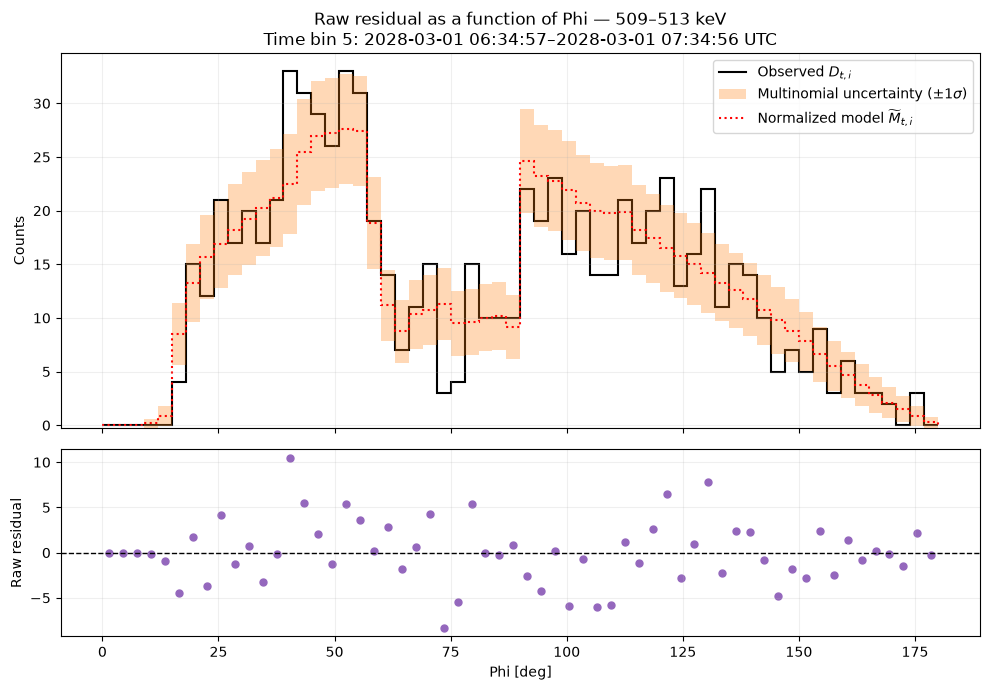

In [8]:
# Reuse one plotter for every view of the selected interval.
time_residual_plotter = PlottingResiduals(time_residual_analysis)

# Compare D(t,i) and M_tilde(t,i), then show their raw residual.
time_phi_raw_figure = time_residual_plotter.plot(
    "Phi_projection",
    residual_type="raw",
)


### Pearson residual view

The Pearson plot uses the same selected temporal products and displays $(D_{t,i}-\widetilde M_{t,i})/\sqrt{\widetilde M_{t,i}}$. Positive residuals indicate more observed counts than predicted in that CDS region; negative residuals indicate fewer. The fixed $[-5,5]$ panel and green $\pm1\sigma$, $\pm2\sigma$, and $\pm3\sigma$ guides make intervals easy to compare, but these Gaussian guides are approximate visual references, not exact multinomial significance thresholds.

For temporal analyses, Monte Carlo references condition on the observed interval total and draw full-CDS counts from a multinomial distribution. Compare the observed Pearson-residual histogram with the multinomial Monte Carlo mean and its pointwise interval: broad agreement supports consistency with the fixed model shape, while systematic shifts, wider tails, or repeated outliers motivate further investigation. The 50 simulations below are only a quick, reproducible demonstration; use a substantially larger ensemble for quantitative interpretation.


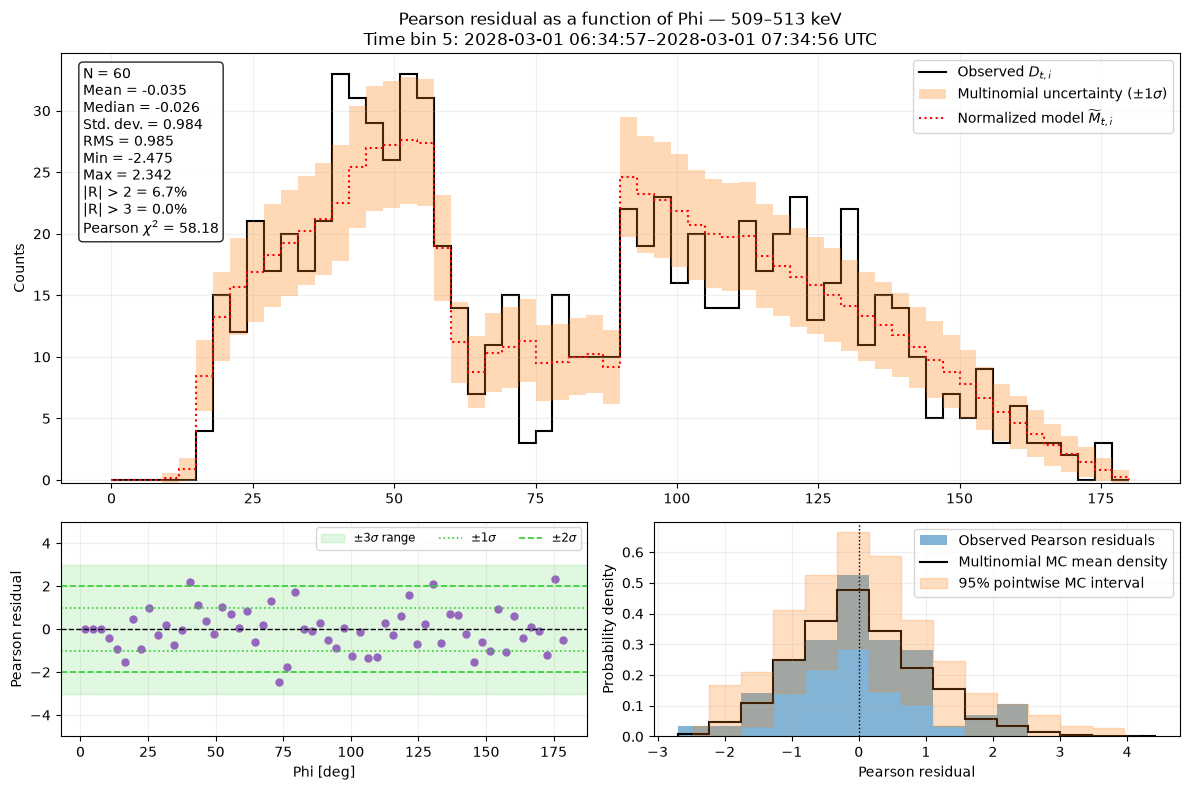

In [9]:
# Display temporal Pearson residuals with a multinomial reference.
time_phi_pearson_figure = time_residual_plotter.plot(
    "Phi_projection",
    residual_type="pearson",
    n_simulations=50,
    random_seed=42,
)


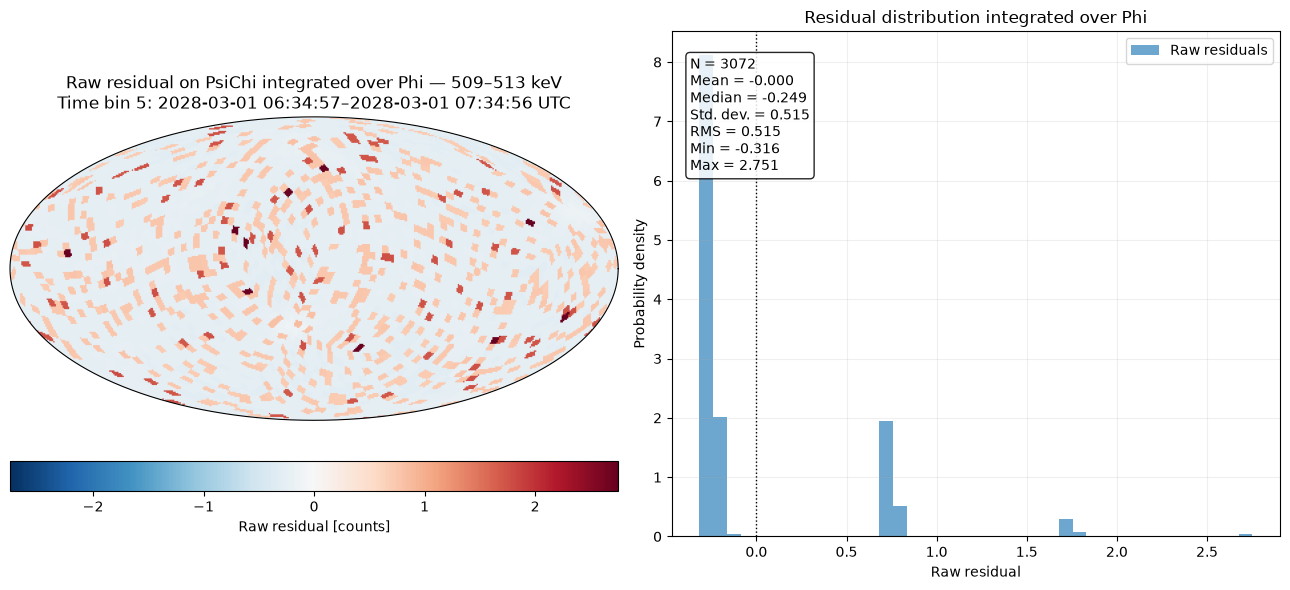

In [10]:
# Display a Phi-integrated temporal residual map on PsiChi.
time_psichi_raw_figure = time_residual_plotter.plot(
    "PsiChi_projection",
    residual_type="raw",
)


## What happens internally

The three classes have distinct roles: `TimeResolvedResidualAnalysis` reconstructs and validates $D_{t,i}$ and normalizes the integrated model; `ResidualAnalysis` selects one interval and applies the existing masks, projections, residual definitions, and Monte Carlo references; `PlottingResiduals` visualizes those results with the selected index and UTC boundaries.

When temporal mode is active, `ResidualAnalysis` performs the following sequence before applying its ordinary mask and projection logic:

1. Instantiate `TimeResolvedResidualAnalysis` from the integrated histograms and weekly products.
2. Combine the weekly histograms into $D_{t,i}$.
3. Verify that $\sum_t D_{t,i}=D_i$.
4. Construct $\widetilde M_{t,i}=N_tM_i/\sum_jM_j$.
5. Verify that $\sum_i\widetilde M_{t,i}=N_t$ for every time bin.
6. Copy the requested interval into matching CDS-only histograms.
7. Continue through the existing `ResidualAnalysis` workflow.

These operations are automatic. Users provide the original $D_i$, original $M_i$, weekly binned observations, and the desired index; they do not construct or pass $\widetilde M_{t,i}$ themselves.
